## Problem Formulation for Narrative Motifs

Given an $ n \times n $ matrix $ M $, where each cell $ M_{i,j} $ can take a value of either 0 or 1:
$$
M = \begin{bmatrix}
    M_{0,0} & M_{0,1} & \dots & M_{0,n-1} \\
    M_{1,0} & M_{1,1} & \dots & M_{1,n-1} \\
    \vdots & \vdots & \ddots & \vdots \\
    M_{n-1,0} & M_{n-1,1} & \dots & M_{n-1,n-1} \\
\end{bmatrix}
$$

### Constraints:

1. **Exact Number of Nodes**:

$$
\sum_{i=0}^{n-1} \sum_{j=0}^{n-1} M_{i,j} = n
$$

2. **Minimum Columns with Nodes**:

$$
\sum_{k=0}^{n-1} \left( \sum_{i=0}^{n-1} M_{i,k} > 0 \right) \geq 2
$$

where the notation $\left( \sum_{i=0}^{n-1} M_{i,k} > 0 \right)$ represents a piecewise function that returns 1 if the inner sum is greater than zero and 0 otherwise.

3. **No Isolated Timeframes**:

For $ k $ from 0 to $ n-2 $:

$$
\left( \sum_{i=0}^{n-1} M_{i,k} = 0 \right) \implies \left( \sum_{i=0}^{n-1} M_{i,k+1} = 0 \right)
$$

### Objective:

Find all distinct matrices $ M $ that satisfy the above constraints. Two matrices $ M $ and $ N $ are considered identical if they can be transformed into each other by swapping rows.

In [3]:
import itertools
import numpy as np
import matplotlib.pyplot as plt

def valid_configuration_general(matrix, n):
    '''
    Check if a matrix configuration is valid based on the constraints for a general n x n grid.
    '''
    # Ensure exactly n nodes
    if np.sum(matrix) != n:
        return False
    
    # Ensure at least two columns have nodes
    col_sums = np.sum(matrix, axis=0)
    if np.sum(col_sums > 0) < 2:
        return False
    
    # Ensure no empty column exists between non-empty columns
    for i in range(n-1):
        if col_sums[i] == 0 and col_sums[i+1] != 0:
            return False
    
    return True

def find_narrative_motifs(n):
    '''
    Find all valid narrative motifs for a general n x n grid.
    '''
    configurations = []
    unique_configs = set()

    for matrix in itertools.product([0, 1], repeat=n*n):
        matrix = np.array(matrix).reshape(n, n)
        if valid_configuration_general(matrix, n):
            # Convert matrix to tuple for hashing
            matrix_tuple = tuple(map(tuple, matrix))
            if matrix_tuple not in unique_configs:
                unique_configs.add(matrix_tuple)
                
                # Add all row permutations to the set
                for perm in itertools.permutations(matrix_tuple):
                    unique_configs.add(perm)
                
                configurations.append(matrix)
    
    return configurations

def visualize_narrative_motifs(configurations, n):
    '''
    Visualize the valid narrative motifs for a general n x n grid.
    '''
    num_configs = len(configurations)
    cols = 4  # Number of subplot columns
    rows = (num_configs + cols - 1) // cols  # Calculate the number of rows needed
    
    fig, axs = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))
    
    # If there's only one row, axs is 1-dimensional
    if rows == 1:
        axs = axs.reshape(1, -1)
    
    for i in range(rows):
        for j in range(cols):
            idx = i*cols + j
            if idx < num_configs:
                axs[i, j].imshow(configurations[idx], cmap="gray_r")
                axs[i, j].axis('off')
                axs[i, j].set_title(f"Motif {idx+1}")
            else:
                axs[i, j].axis('off')  # Turn off remaining subplots

    plt.suptitle(f"Narrative Motifs for {n}x{n} Grid with {n} Nodes")
    plt.tight_layout()
    plt.show()
 



## Problem Formulation for Narrative Motifs (3 nodes)

Given a $3 \times 3$ matrix $ M $, where each cell $ M_{i,j} $ can take a value of either 0 or 1:

$$
M = \begin{bmatrix}
    M_{0,0} & M_{0,1} & M_{0,2} \\
    M_{1,0} & M_{1,1} & M_{1,2} \\
    M_{2,0} & M_{2,1} & M_{2,2} \\
\end{bmatrix}
$$

### Constraints:

1. **Exact Number of Nodes**: The matrix should contain exactly 3 nodes:

$$
\sum_{i=0}^{2} \sum_{j=0}^{2} M_{i,j} = 3
$$

2. **Minimum Columns with Nodes**: At least two columns in the matrix should have nodes. This ensures there's more than one timeframe represented.

3. **No Isolated Timeframes**: If a column (representing a timeframe) is empty, then all columns to its right should also be empty. For instance, if we think of the columns as "Past", "Present", and "Future", we can't have nodes in "Past" and "Future" without anything in the "Present".

Mathematically, if the first column is empty, the second column should also be empty:

$$
\left( \sum_{i=0}^{2} M_{i,0} = 0 \right) \implies \left( \sum_{i=0}^{2} M_{i,1} = 0 \right)
$$

Similarly, if the second column is empty, the third column should also be empty:

$$
\left( \sum_{i=0}^{2} M_{i,1} = 0 \right) \implies \left( \sum_{i=0}^{2} M_{i,2} = 0 \right)
$$


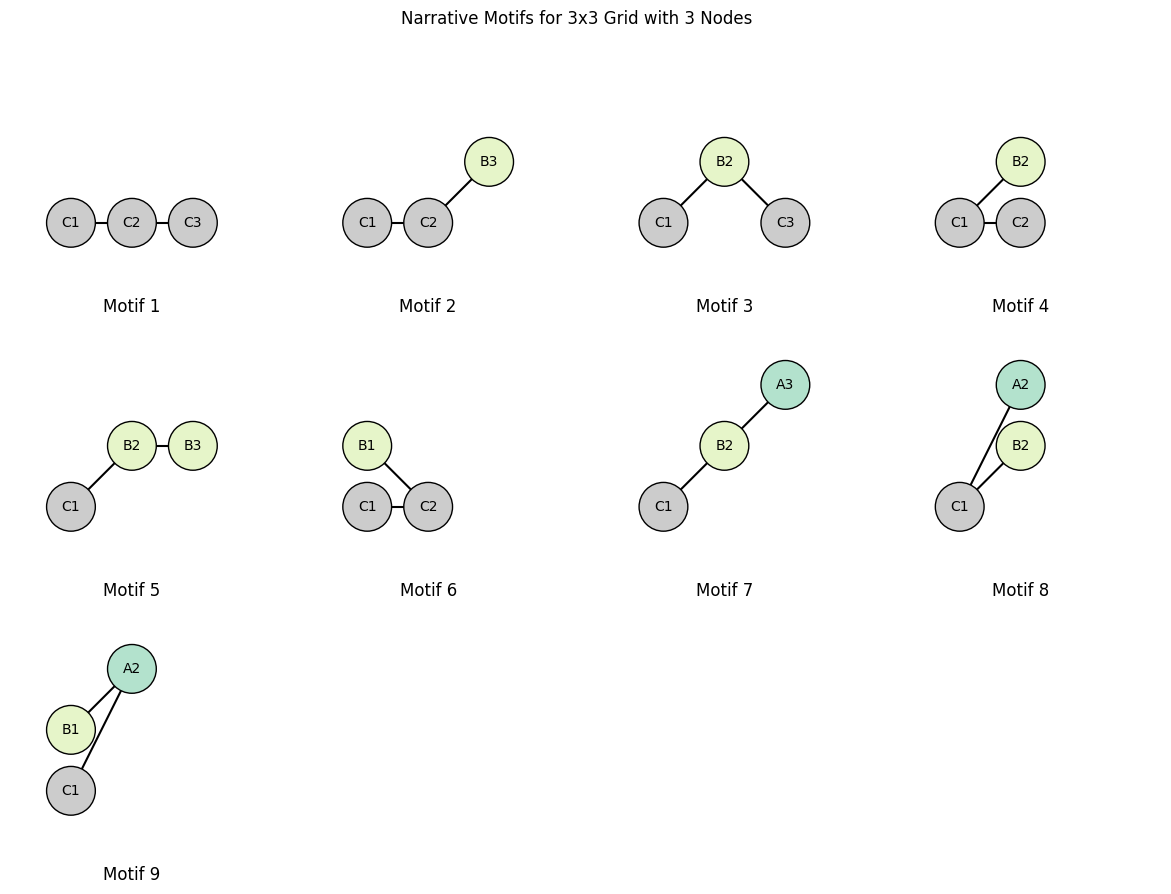

In [51]:
def visualize_narrative_motifs_with_labels(configurations, n):
    """
    Visualize the valid narrative motifs for a general n x n grid using colored circles for nodes, edges, and labels.
    """
    num_configs = len(configurations)
    cols = 4  # Number of subplot columns
    rows = (num_configs + cols - 1) // cols  # Calculate the number of rows needed
    
    # Colors for each row
    colors = plt.cm.Pastel2(np.linspace(0, 1, n))
    
    # Labels for nodes
    labels = [chr(65 + i) for i in range(n)]  # Generate labels 'A', 'B', 'C', ...
    
    fig, axs = plt.subplots(rows, cols, figsize=(3*cols, 3*rows))
    
    # If there's only one row, axs is 1-dimensional
    if rows == 1:
        axs = axs.reshape(1, -1)
    
    for i in range(rows):
        for j in range(cols):
            idx = i*cols + j
            ax = axs[i, j]
            if idx < num_configs:
                matrix = configurations[idx]
                
                # Draw nodes
                for x in range(n):
                    for y in range(n):
                        if matrix[y, x] == 1:
                            circle = plt.Circle((x, n-1-y), 0.4, color=colors[y], ec="black", zorder=2)
                            ax.add_patch(circle)
                            # Add label to the node
                            ax.text(x, n-1-y, f"{labels[y]}{x+1}", color='black',
                                    ha='center', va='center', zorder=3)
                            
                # Draw edges between nodes in adjacent columns
                for x in range(n-1):
                    for y1 in range(n):
                        for y2 in range(n):
                            if matrix[y1, x] == 1 and matrix[y2, x+1] == 1:
                                ax.plot([x, x+1], [n-1-y1, n-1-y2], color='black', zorder=1)
                
                ax.set_xlim(-1, n)
                ax.set_ylim(-1, n)
                ax.axis('off')
                ax.set_aspect('equal', 'box')
                ax.set_title(f"Motif {idx+1}", y=-0.15)
            else:
                ax.axis('off')  # Turn off remaining subplots

    plt.suptitle(f"Narrative Motifs for {n}x{n} Grid with {n} Nodes")
    plt.tight_layout()
    plt.show()

# Visualize the narrative motifs for a 4x4 grid with 4 nodes using colored circles, edges, and labels
n = 3
configurations = find_narrative_motifs(n)
visualize_narrative_motifs_with_labels(configurations, n)

